# Etapa 3 · Explorando Stockfish con mis partidas

**Pregunta:** ¿qué dicen las evaluaciones de Stockfish sobre cómo juego, y sirven como etiquetas
para entrenar el clasificador de jugadas de la Etapa 4?

**Datos:** mis 1.000 partidas más recientes en chess.com (`weytey`), analizadas jugada a jugada con
Stockfish 19 a profundidad 12. Son unas 75.000 jugadas, la mitad mías.

Para regenerarlos:

```bat
python scripts\download_games.py download
python -m scripts.analyze_games --games 1000 --depth 12
```

El análisis lo hace `app/analysis.py`. Para cada jugada compara la posición **antes** (con la mejor
jugada posible) y **después** de la jugada real.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Funciona tanto abriendo Jupyter desde la raíz del repo como desde notebooks/.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from app.analysis import ETIQUETAS, UMBRALES, win_probability  # noqa: E402

df = pd.read_csv(RAIZ / "data" / "analysis" / "moves.csv")

# Estilo: superficie clara, rejilla discreta, texto en tinta neutra (no del color de la serie).
TINTA, TINTA_2, SUPERFICIE, REJILLA = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
YO, RIVAL = "#2a78d6", "#eb6834"  # paleta categórica validada (slots 1 y 2)
RAMPA = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # ordinal: buena → error grave
NOMBRES = {"buena": "buena", "imprecision": "imprecisión", "error": "error", "error_grave": "error grave"}
plt.rcParams.update(
    {
        "figure.facecolor": SUPERFICIE,
        "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE,
        "axes.edgecolor": REJILLA,
        "axes.labelcolor": TINTA_2,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "text.color": TINTA,
        "axes.grid": True,
        "grid.color": REJILLA,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "figure.dpi": 110,
        "lines.linewidth": 2,
    }
)

yo = df[df.is_user].copy()
rivales = df[~df.is_user].copy()
print(f"{df.game_id.nunique()} partidas · {len(df):,} jugadas · {len(yo):,} mías")
df.drop_duplicates("game_id").time_control.value_counts().rename("partidas por ritmo (segundos)").to_frame()

1000 partidas · 75,251 jugadas · 37,637 mías


,partidas por ritmo (segundos)
time_control,
180,967
600,25
60,8


## 1. De centipeones a probabilidad de ganar

Stockfish evalúa en **centipeones** (cp): +100 significa que blancas tienen la ventaja de un peón.
El problema es que los cp no tienen el mismo peso en cualquier posición. Perder 100 cp con la
partida igualada puede decidirla; perderlos ganando por +900 no cambia nada.

Por eso se pasa a **probabilidad de ganar** con una sigmoide (la constante es la de Lichess):

$$P(\text{ganar}) = 50 + 50\left(\frac{2}{1 + e^{-0.00368\,\text{cp}}} - 1\right)$$

La etiqueta de cada jugada depende de **cuántos puntos de probabilidad pierde** quien mueve.

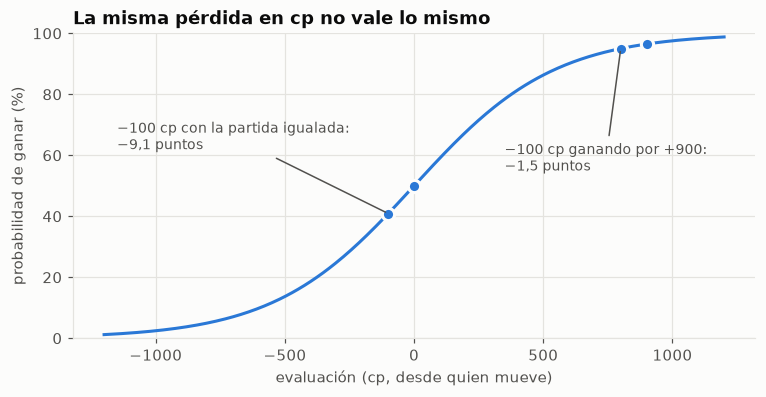

,etiqueta,pierde al menos (puntos de probabilidad)
0,imprecisión,5.0
1,error,10.0
2,error grave,20.0


In [2]:
cp = np.linspace(-1200, 1200, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(cp, [win_probability(c) for c in cp], color=YO)
for x in (0, -100, 800, 900):
    ax.plot(x, win_probability(x), "o", color=YO, markersize=8, markeredgecolor=SUPERFICIE, markeredgewidth=2)
d_igual = win_probability(0) - win_probability(-100)
d_ganando = win_probability(900) - win_probability(800)
ax.annotate(
    f"−100 cp con la partida igualada:\n−{d_igual:.1f} puntos".replace(".", ","),
    xy=(-100, win_probability(-100)),
    xytext=(-1150, 62),
    color=TINTA_2,
    fontsize=9,
    arrowprops=dict(arrowstyle="-", color=TINTA_2),
)
ax.annotate(
    f"−100 cp ganando por +900:\n−{d_ganando:.1f} puntos".replace(".", ","),
    xy=(800, win_probability(800)),
    xytext=(350, 55),
    color=TINTA_2,
    fontsize=9,
    arrowprops=dict(arrowstyle="-", color=TINTA_2),
)
ax.set(
    title="La misma pérdida en cp no vale lo mismo",
    xlabel="evaluación (cp, desde quien mueve)",
    ylabel="probabilidad de ganar (%)",
    ylim=(0, 100),
)
plt.show()

pd.DataFrame(
    {
        "etiqueta": [NOMBRES[e] for e, _ in UMBRALES][::-1],
        "pierde al menos (puntos de probabilidad)": [u for _, u in UMBRALES][::-1],
    }
)

## 2. Una partida, jugada a jugada

La curva es mi probabilidad de ganar después de cada jugada. Los puntos marcan mis errores. Así
se ve dónde se decidió la partida.

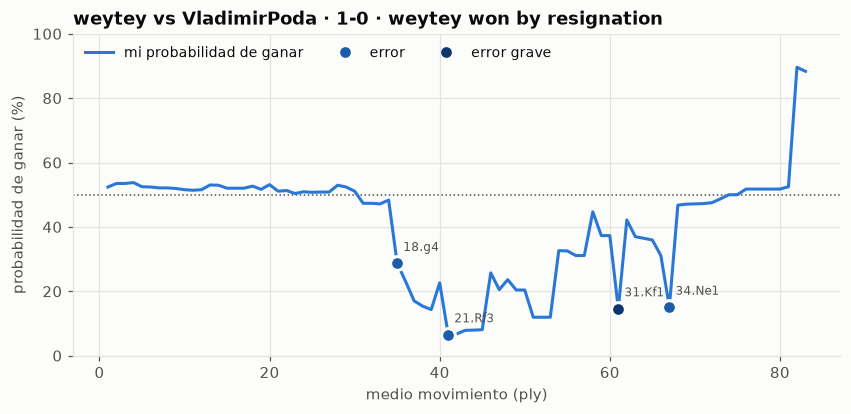

https://www.chess.com/game/live/185612836622


,ply,san,best_uci,eval_before,eval_after,win_drop,label
75155,35,g4,a1b1,-18,-247,19.63,error
75161,41,Rf3,d3g3,-334,-722,16.07,error
75181,61,Kf1,c1e1,-141,-479,22.67,error_grave
75187,67,Ne1,f3d2,-216,-469,16.00,error


In [3]:
def mi_win(fila):
    # win_after está desde quien mueve: si movió el rival, mi probabilidad es 100 - la suya.
    return fila.win_after if fila.is_user else 100 - fila.win_after


candidatas = yo[yo.label == "error_grave"].groupby("game_id").size().index
partida_id = (
    df[df.game_id.isin(candidatas)]
    .groupby("game_id")
    .filter(lambda g: 50 <= len(g) <= 90)
    .sort_values("utc_datetime")
    .game_id.iloc[-1]
)
p = df[df.game_id == partida_id].sort_values("ply").copy()
p["mi_win"] = p.apply(mi_win, axis=1)
cab = p.iloc[0]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(50, color=TINTA_2, linewidth=1, linestyle=":")
ax.plot(p.ply, p.mi_win, color=YO, label="mi probabilidad de ganar")
errores = p[p.is_user & p.label.isin(["error", "error_grave"])]
for _, e in errores.iterrows():
    ax.plot(
        e.ply,
        e.mi_win,
        "o",
        markersize=9,
        color=RAMPA[3] if e.label == "error_grave" else RAMPA[2],
        markeredgecolor=SUPERFICIE,
        markeredgewidth=2,
    )
    ax.annotate(
        f"{(e.ply + 1) // 2}{'.' if e.mover == 'white' else '...'}{e.san}",
        (e.ply, e.mi_win),
        textcoords="offset points",
        xytext=(4, 8),
        fontsize=8,
        color=TINTA_2,
    )
ax.set(
    title=f"{cab.white} vs {cab.black} · {cab.result} · {cab.termination}",
    xlabel="medio movimiento (ply)",
    ylabel="probabilidad de ganar (%)",
    ylim=(0, 100),
)
ax.plot([], [], "o", color=RAMPA[2], label="error")
ax.plot([], [], "o", color=RAMPA[3], label="error grave")
ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=3)
plt.show()
print(cab.game_id)
errores[["ply", "san", "best_uci", "eval_before", "eval_after", "win_drop", "label"]]

## 3. ¿Cuántos centipeones pierdo por jugada? (estadística descriptiva)

La pérdida por jugada (*cp_loss*) tiene una distribución muy **asimétrica**. La mayoría de las
jugadas pierden casi nada y unas pocas pierden muchísimo. Por eso la **media** y la **mediana**
cuentan historias distintas.

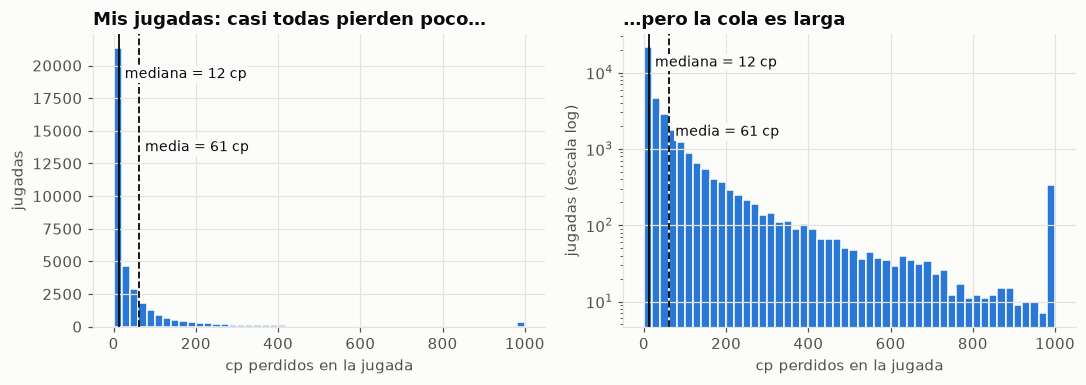

,count,mean,std,min,25%,50%,75%,90%,99%,max
cp_loss (mis jugadas),37637.0,61.3,140.7,0.0,0.0,12.0,54.0,155.0,896.3,1000.0


In [4]:
desc = yo.cp_loss.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.arange(0, 1001, 20)
for ax, escala in zip(axes, ["linear", "log"], strict=True):
    ax.hist(yo.cp_loss, bins=bins, color=YO, edgecolor=SUPERFICIE, linewidth=1)
    ax.set_yscale(escala)
    for valor, nombre, alto in [(yo.cp_loss.median(), "mediana", 0.85), (yo.cp_loss.mean(), "media", 0.6)]:
        ax.axvline(valor, color=TINTA, linewidth=1.2, linestyle="--" if nombre == "media" else "-")
        y = ax.get_ylim()[1] * (alto if escala == "linear" else alto**6)
        ax.text(
            valor + 15,
            y,
            f"{nombre} = {valor:.0f} cp",
            fontsize=9,
            color=TINTA,
            bbox=dict(facecolor=SUPERFICIE, edgecolor="none", pad=1),
        )
    ax.set(xlabel="cp perdidos en la jugada", ylabel="jugadas" + (" (escala log)" if escala == "log" else ""))
axes[0].set_title("Mis jugadas: casi todas pierden poco…")
axes[1].set_title("…pero la cola es larga")
plt.tight_layout()
plt.show()
desc.to_frame("cp_loss (mis jugadas)").T

**Lectura:**
- **Mediana de unos 12 cp:** la jugada típica es casi perfecta.
- **Media de unos 61 cp**, cinco veces la mediana: la empujan las pocas jugadas muy malas (el
  percentil 99 está cerca de 900, es decir, piezas regaladas o mates fallados).
- **Desviación típica de unos 140**, mayor que la propia media: es la firma de una distribución
  con cola larga.

Para describir "cómo juego normalmente", la mediana es más honesta. Para medir "cuánto me
cuestan los errores", la media (el ACPL) sí sirve, porque es justo la que pesa la cola.

## 4. Mis jugadas frente a las de mis rivales

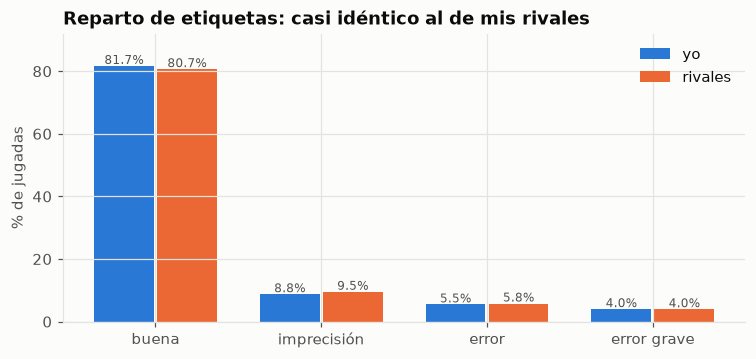

,yo,rivales
label,,
buena,81.7,80.7
imprecision,8.8,9.5
error,5.5,5.8
error_grave,4.0,4.0


In [5]:
reparto = (
    pd.DataFrame(
        {
            "yo": yo.label.value_counts(normalize=True),
            "rivales": rivales.label.value_counts(normalize=True),
        }
    ).reindex(ETIQUETAS)
    * 100
)

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(ETIQUETAS))
w = 0.38
for i, (col, color) in enumerate([("yo", YO), ("rivales", RIVAL)]):
    barras = ax.bar(x + (i - 0.5) * w, reparto[col], width=w - 0.02, color=color, label=col)
    for b in barras:
        ax.text(
            b.get_x() + b.get_width() / 2,
            b.get_height() + 0.6,
            f"{b.get_height():.1f}%",
            ha="center",
            fontsize=8,
            color=TINTA_2,
        )
ax.set_xticks(x, [NOMBRES[e] for e in ETIQUETAS])
ax.set(title="Reparto de etiquetas: casi idéntico al de mis rivales", ylabel="% de jugadas")
ax.set_ylim(0, 92)
ax.legend(frameon=False)
plt.show()
reparto.round(1)

Juego al nivel de mis rivales, lo cual es lógico: el emparejamiento de chess.com busca justo eso.
Para la Etapa 4 hay un dato decisivo: **en torno al 82 % de las jugadas son "buenas"**. Un
clasificador que dijera siempre "buena" acertaría el 82 % sin aprender nada. Habrá que medir con
métricas por clase (precisión y *recall* de los errores) y no con el acierto global.

## 5. ¿En qué fase de la partida fallo más?

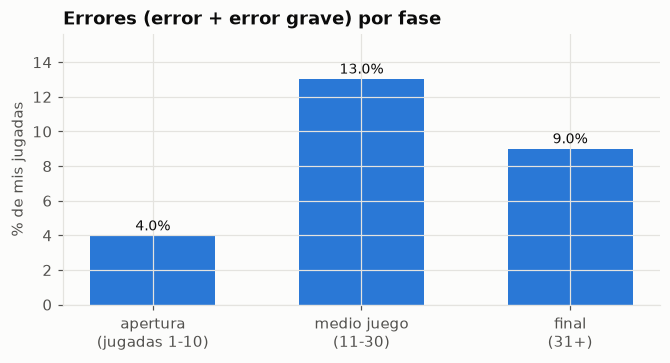

,jugadas,% errores
fase,,
apertura (jugadas 1-10),9953,4.0
medio juego (11-30),17103,13.0
final (31+),10581,9.0


In [6]:
fases = pd.cut(
    yo.ply, [0, 20, 60, 999], labels=["apertura\n(jugadas 1-10)", "medio juego\n(11-30)", "final\n(31+)"]
)
por_fase = (
    yo.assign(fase=fases)
    .groupby("fase", observed=True)
    .label.apply(lambda s: s.isin(["error", "error_grave"]).mean() * 100)
)
n_fase = yo.assign(fase=fases).groupby("fase", observed=True).size()

fig, ax = plt.subplots(figsize=(7, 3.2))
barras = ax.bar(range(len(por_fase)), por_fase, color=YO, width=0.6)
for b, v in zip(barras, por_fase, strict=True):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9, color=TINTA)
ax.set_xticks(range(len(por_fase)), por_fase.index)
ax.set(
    title="Errores (error + error grave) por fase", ylabel="% de mis jugadas", ylim=(0, por_fase.max() * 1.2)
)
plt.show()
pd.DataFrame({"jugadas": n_fase, "% errores": por_fase.round(1)}).rename(index=lambda i: i.replace("\n", " "))

La apertura es mi zona segura, con unos 4 de cada 100 jugadas: es teoría memorizada y
posiciones conocidas. **En el medio juego los errores se triplican.** Es la fase con más
decisiones abiertas, justo donde un coach puede aportar más. Es una pista para el RAG de
aperturas (Etapa 5A): el valor no está tanto en la teoría como en los planes típicos que salen de
ella.

## 6. ¿Juego peor en las partidas que pierdo? Intervalo de confianza

Por partida calculo el **ACPL**, la pérdida media de centipeones en mis jugadas. Una diferencia
entre victorias y derrotas en *esta muestra* podría deberse al azar de qué partidas cayeron en
ella. El **intervalo de confianza** responde a esa duda: es el rango de valores compatible con los
datos para la diferencia *real*.

Lo calculo con **bootstrap**:
1. Remuestreo las partidas con reemplazo, 5.000 veces.
2. Recalculo la diferencia en cada remuestreo.
3. Me quedo con el 95 % central de esas diferencias.

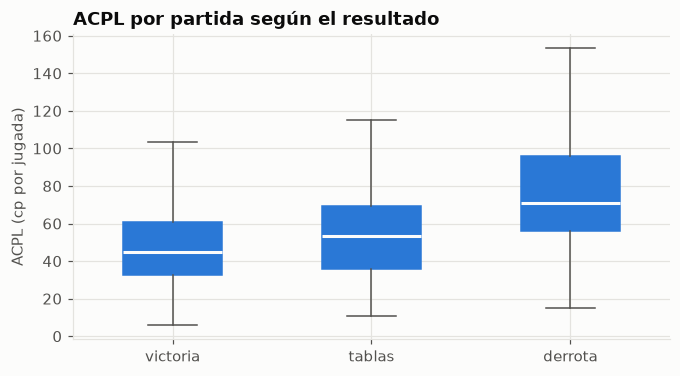

Diferencia de ACPL (derrotas − victorias): 28.8 cp
Intervalo de confianza del 95 % (bootstrap): [24.9, 32.6] cp


,count,mean,median,std
resultado,,,,
victoria,496,49.8,45.1,25.6
tablas,44,55.4,53.5,28.2
derrota,460,78.6,70.9,34.2


In [7]:
def resultado_mio(fila):
    if fila.result == "1/2-1/2":
        return "tablas"
    return "victoria" if (fila.result == "1-0") == (fila.user_color == "white") else "derrota"


por_partida = yo.groupby("game_id").agg(
    acpl=("cp_loss", "mean"), result=("result", "first"), user_color=("user_color", "first")
)
por_partida["resultado"] = por_partida.apply(resultado_mio, axis=1)
orden = ["victoria", "tablas", "derrota"]

fig, ax = plt.subplots(figsize=(7, 3.6))
datos = [por_partida.loc[por_partida.resultado == r, "acpl"] for r in orden]
caja = ax.boxplot(
    datos,
    tick_labels=orden,
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color=SUPERFICIE, linewidth=2),
)
for parche in caja["boxes"]:
    parche.set(facecolor=YO, edgecolor=YO)
for linea in caja["whiskers"] + caja["caps"]:
    linea.set(color=TINTA_2)
ax.set(title="ACPL por partida según el resultado", ylabel="ACPL (cp por jugada)")
plt.show()

rng = np.random.default_rng(42)
der = por_partida.loc[por_partida.resultado == "derrota", "acpl"].to_numpy()
vic = por_partida.loc[por_partida.resultado == "victoria", "acpl"].to_numpy()
difs = np.array([rng.choice(der, der.size).mean() - rng.choice(vic, vic.size).mean() for _ in range(5000)])
lo, hi = np.percentile(difs, [2.5, 97.5])
print(f"Diferencia de ACPL (derrotas − victorias): {der.mean() - vic.mean():.1f} cp")
print(f"Intervalo de confianza del 95 % (bootstrap): [{lo:.1f}, {hi:.1f}] cp")
por_partida.groupby("resultado").acpl.agg(["count", "mean", "median", "std"]).reindex(orden).round(1)

**Cómo leerlo:** en las derrotas pierdo unos 29 cp más por jugada. El intervalo del 95 % (unos
25 a 33 cp) **no incluye el 0**, así que la diferencia no es casualidad de la muestra.

Ojo con la causalidad, que va en los dos sentidos. Jugar peor hace perder, pero perder también
infla el ACPL: cuando una partida ya está perdida se arriesga más y las jugadas "malas" abundan.
El intervalo dice *cuánto* difieren, no *por qué*.

## 7. Presión de tiempo y una variable de confusión

Casi todas son partidas de 3 minutos, y chess.com guarda el reloj tras cada jugada. ¿Fallo más
con poco tiempo?

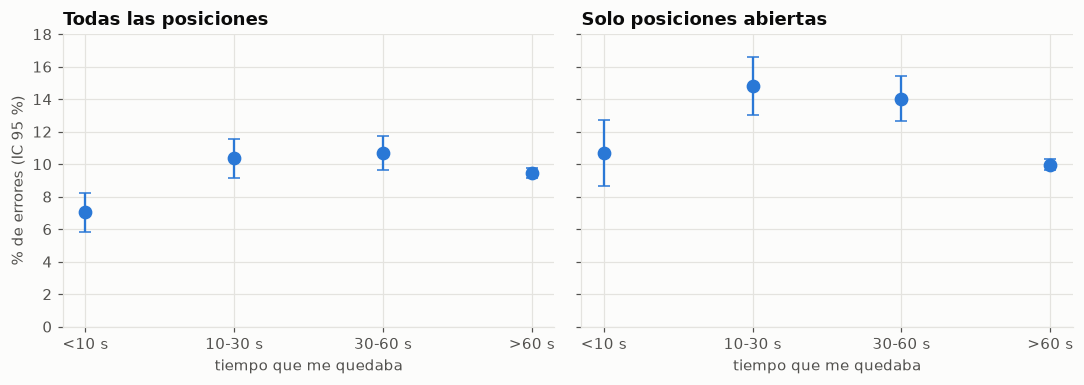

,jugadas,% posiciones ya decididas,% errores (todas),% errores (abiertas),cp_loss medio (abiertas)
reloj,,,,,
<10 s,1765,51.0,7.0,10.7,72.0
10-30 s,2519,39.0,10.4,14.8,78.0
30-60 s,3517,31.0,10.7,14.0,69.0
>60 s,29836,11.0,9.5,10.0,50.0


In [8]:
con_reloj = yo.dropna(subset=["clock_after"]).copy()
con_reloj["reloj"] = pd.cut(
    con_reloj.clock_after, [-1, 10, 30, 60, 1e9], labels=["<10 s", "10-30 s", "30-60 s", ">60 s"]
)
con_reloj["decidida"] = (con_reloj.win_before - 50).abs() > 40  # una de las dos tiene >90 %
con_reloj["error"] = con_reloj.label.isin(["error", "error_grave"])


def tasa_con_ic(s):
    p, n = s.mean(), s.size
    m = 1.96 * np.sqrt(p * (1 - p) / n)  # aproximación normal de una proporción
    return pd.Series({"n": n, "%": 100 * p, "ic_bajo": 100 * (p - m), "ic_alto": 100 * (p + m)})


todas = con_reloj.groupby("reloj", observed=True).error.apply(tasa_con_ic).unstack()
abiertas = con_reloj[~con_reloj.decidida].groupby("reloj", observed=True).error.apply(tasa_con_ic).unstack()
pct_decididas = con_reloj.groupby("reloj", observed=True).decidida.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
x = np.arange(len(todas))
for ax, tabla, titulo in [
    (axes[0], todas, "Todas las posiciones"),
    (axes[1], abiertas, "Solo posiciones abiertas"),
]:
    ax.errorbar(
        x,
        tabla["%"],
        yerr=[tabla["%"] - tabla.ic_bajo, tabla.ic_alto - tabla["%"]],
        fmt="o",
        color=YO,
        markersize=8,
        capsize=4,
        elinewidth=1.5,
    )
    ax.set_xticks(x, todas.index)
    ax.set(title=titulo, xlabel="tiempo que me quedaba", ylim=(0, 18))
axes[0].set_ylabel("% de errores (IC 95 %)")
plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "jugadas": todas.n.astype(int),
        "% posiciones ya decididas": pct_decididas.round(0),
        "% errores (todas)": todas["%"].round(1),
        "% errores (abiertas)": abiertas["%"].round(1),
        "cp_loss medio (abiertas)": con_reloj[~con_reloj.decidida]
        .groupby("reloj", observed=True)
        .cp_loss.mean()
        .round(0),
    }
)

**La paradoja:** mirando todas las posiciones, con menos de 10 s parece que cometo *menos*
errores que con 10-60 s. ¿La presión me ayuda?

No. La tabla tiene la explicación: con menos de 10 s, **la mitad de las posiciones ya están
decididas**, frente a 1 de cada 9 con más de un minuto. Cuando una partida está ganada o perdida,
perder material casi no mueve la probabilidad de ganar (sección 1), y la etiqueta no lo cuenta
como error. La **fase de la partida** es una *variable de confusión*: influye a la vez en el
reloj y en la etiqueta.

Si se miran solo las posiciones abiertas, la presión sí se nota:
- **La tasa de errores sube a un 14-15 % entre 10 y 60 s**, frente a un 10 % con más de un
  minuto.
- **La pérdida media pasa de unos 50 cp a 72-78 cp** con menos de 30 s.

Con menos de 10 s el intervalo es ancho (hay pocas jugadas abiertas), así que no da para concluir
nada sobre ese tramo.

## 8. Conclusiones para la Etapa 4 (clasificador de jugadas)

1. **Las etiquetas de Stockfish son utilizables**, pero la definición importa. Basarlas en la
   caída de probabilidad (y no en cp) evita marcar como error lo que no cambia nada, a cambio de
   no marcar regalos en posiciones ya decididas. Hay que decidirlo a propósito.
2. **Las clases están desbalanceadas**, con un 82 % de jugadas buenas. Habrá que usar métricas por
   clase y pesos de clase o un muestreo equilibrado.
3. **Variables candidatas** (*features*):
   - evaluación previa y cuánta ventaja hay (si la posición está decidida o no);
   - fase o número de jugada;
   - tiempo en el reloj;
   - material sobre el tablero;
   - si hay jaque o captura disponible;
   - número de jugadas legales (la complejidad).
4. **Validar por partidas, no por jugadas.** Las jugadas de una misma partida se parecen entre sí.
   Si unas van a entrenamiento y otras a prueba de la misma partida, el modelo "hace trampa".
5. **Profundidad 12 es suficiente para explorar.** Para las etiquetas definitivas conviene subirla
   y comprobar cuánto cambian.